# Gemini Unraveling Output Token Counts

Randomly sample one problem from each selected batch and count Gemini output tokens for both approaches: regular formalizer (`problem.pddl`) and higher-order formalizer (`generator.py`). This notebook only reads existing files and displays results in memory; it does not write result files.


In [2]:
# Optional dependency setup for SageMaker/Jupyter environments.
%pip install -U google-genai

  Using cached google_genai-2.11.0-py3-none-any.whl.metadata (55 kB)


Using cached google_genai-2.11.0-py3-none-any.whl (984 kB)


Note: you may need to restart the kernel to use updated packages.


In [3]:
# Cell 1: Setup imports, project paths, Gemini client, and selected batch ranges
from pathlib import Path
import os
import random

from dotenv import load_dotenv
from google import genai


def find_project_root() -> Path:
    candidates = [Path.cwd(), Path.cwd().parent]
    for candidate in candidates:
        if (candidate / "data").exists() and (candidate / "src").exists():
            return candidate.resolve()
    raise RuntimeError("Could not locate project root from current working directory.")


PROJECT_ROOT = find_project_root()
REGULAR_OUTPUT_BASE = PROJECT_ROOT / "output" / "direct_pddl_direct_unraveling"
HIGHER_ORDER_OUTPUT_BASE = PROJECT_ROOT / "output" / "direct_pddl_unraveling"

load_dotenv(PROJECT_ROOT / ".env")
GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY")
if not GOOGLE_API_KEY:
    raise ValueError("GOOGLE_API_KEY not found in .env")

client = genai.Client(api_key=GOOGLE_API_KEY)
MODEL_NAME = "gemini-3-flash-preview"

# Set to an integer for reproducible random sampling. Change if you want a different random draw.
RANDOM_SEED = 27

APPROACH_OUTPUT_SPECS = {
    "regular_formalizer": {
        "output_base": REGULAR_OUTPUT_BASE,
        "artifact_name": "problem.pddl",
        "description": "regular direct-PDDL output",
    },
    "higher_order_formalizer": {
        "output_base": HIGHER_ORDER_OUTPUT_BASE,
        "artifact_name": "generator.py",
        "description": "higher-order Python generator output",
    },
}

DOMAIN_RELATIVE_OUTPUT_ROOTS = {
    "BlocksWorld": Path("gemini_3_flash"),
    "OpenStacks": Path("OpenStacks") / "sliding_window_orders" / "gemini_3_flash",
    "Transport": Path("Transport") / "fully_connected_delivery" / "gemini_3_flash",
    "ChildSnack": Path("ChildSnack") / "single_sandwich_line" / "gemini_3_flash",
}

# Each tuple is (batch_label, inclusive_start_problem_number, inclusive_end_problem_number).
DOMAIN_BATCHES = {
    "BlocksWorld": [
        ("5 blocks", 1, 10),
        ("30 blocks", 51, 60),
        ("50 blocks", 91, 100),
        ("75 blocks", 141, 150),
        ("100 blocks", 191, 200),
    ],
    "OpenStacks": [
        ("5 orders", 1, 10),
        ("10 orders", 11, 20),
        ("15 orders", 21, 30),
        ("20 orders", 31, 40),
        ("25 orders", 41, 50),
        ("30 orders", 51, 60),
        ("50 orders", 61, 70),
        ("100 orders", 71, 80),
    ],
    "Transport": [
        ("10 locations", 1, 10),
        ("15 locations", 11, 20),
        ("20 locations", 21, 30),
        ("25 locations", 31, 40),
        ("30 locations", 41, 50),
        ("50 locations", 51, 60),
        ("100 locations", 61, 70),
    ],
    "ChildSnack": [
        ("5 children", 1, 10),
        ("10 children", 11, 20),
        ("15 children", 21, 30),
        ("20 children", 31, 40),
        ("25 children", 41, 50),
        ("30 children", 51, 60),
        ("50 children", 61, 70),
        ("100 children", 71, 80),
    ],
}

print("PROJECT_ROOT:", PROJECT_ROOT)
print("MODEL_NAME:", MODEL_NAME)
print("RANDOM_SEED:", RANDOM_SEED)
for approach, spec in APPROACH_OUTPUT_SPECS.items():
    print(f"{approach} output base exists:", spec["output_base"].exists(), spec["output_base"])

PROJECT_ROOT: /home/sagemaker-user/formalizer-scaling
MODEL_NAME: gemini-3-flash-preview
RANDOM_SEED: 27
regular_formalizer output base exists: True /home/sagemaker-user/formalizer-scaling/output/direct_pddl_direct_unraveling
higher_order_formalizer output base exists: True /home/sagemaker-user/formalizer-scaling/output/direct_pddl_unraveling


In [4]:
# Cell 2: Sampling and token-count helpers
def pid_from_int(i: int) -> str:
    return f"p{i:02d}" if i < 100 else f"p{i}"


def sample_one_problem_per_batch(seed: int | None = RANDOM_SEED) -> list[dict]:
    rng = random.Random(seed)
    samples = []
    for domain, batches in DOMAIN_BATCHES.items():
        for batch_label, start, end in batches:
            problem_num = rng.randint(start, end)
            problem_id = pid_from_int(problem_num)
            samples.append({
                "domain": domain,
                "batch": batch_label,
                "range": f"{pid_from_int(start)}-{pid_from_int(end)}",
                "problem_id": problem_id,
            })
    return samples


def artifact_path_for(approach: str, domain: str, problem_id: str) -> Path:
    spec = APPROACH_OUTPUT_SPECS[approach]
    return (
        spec["output_base"]
        / DOMAIN_RELATIVE_OUTPUT_ROOTS[domain]
        / problem_id
        / "cand_00"
        / spec["artifact_name"]
    )


def expand_samples_by_approach(samples: list[dict]) -> list[dict]:
    rows = []
    for sample in samples:
        for approach, spec in APPROACH_OUTPUT_SPECS.items():
            artifact_path = artifact_path_for(approach, sample["domain"], sample["problem_id"])
            rows.append({
                "approach": approach,
                "artifact": spec["artifact_name"],
                "domain": sample["domain"],
                "batch": sample["batch"],
                "range": sample["range"],
                "problem_id": sample["problem_id"],
                "artifact_path": artifact_path,
            })
    return rows


def count_gemini_tokens(text: str) -> int:
    response = client.models.count_tokens(model=MODEL_NAME, contents=text)
    total_tokens = getattr(response, "total_tokens", None)
    if total_tokens is None:
        raise ValueError(f"Unexpected count_tokens response: {response}")
    return int(total_tokens)


def display_table(rows: list[dict]):
    try:
        import pandas as pd
        from IPython.display import display
        display(pd.DataFrame(rows))
    except Exception:
        for row in rows:
            print(row)


In [5]:
# Cell 3: Randomly sample one problem per batch and verify both approach artifacts exist
samples = sample_one_problem_per_batch(RANDOM_SEED)
artifact_rows = expand_samples_by_approach(samples)
missing = [row for row in artifact_rows if not row["artifact_path"].exists()]

print("Sampled artifacts:")
display_table([
    {
        "approach": row["approach"],
        "artifact": row["artifact"],
        "domain": row["domain"],
        "batch": row["batch"],
        "range": row["range"],
        "problem_id": row["problem_id"],
        "artifact_path": str(row["artifact_path"]),
        "exists": row["artifact_path"].exists(),
    }
    for row in artifact_rows
])

if missing:
    missing_paths = "\n".join(str(row["artifact_path"]) for row in missing)
    raise FileNotFoundError(f"Missing sampled artifact file(s):\n{missing_paths}")


Sampled artifacts:


,approach,artifact,domain,batch,range,problem_id,artifact_path,exists
0,regular_formalizer,problem.pddl,BlocksWorld,5 blocks,p01-p10,p08,/home/sagemaker-user/formalizer-scaling/output...,True
1,higher_order_formalizer,generator.py,BlocksWorld,5 blocks,p01-p10,p08,/home/sagemaker-user/formalizer-scaling/output...,True
2,regular_formalizer,problem.pddl,BlocksWorld,30 blocks,p51-p60,p55,/home/sagemaker-user/formalizer-scaling/output...,True
3,higher_order_formalizer,generator.py,BlocksWorld,30 blocks,p51-p60,p55,/home/sagemaker-user/formalizer-scaling/output...,True
4,regular_formalizer,problem.pddl,BlocksWorld,50 blocks,p91-p100,p95,/home/sagemaker-user/formalizer-scaling/output...,True
5,higher_order_formalizer,generator.py,BlocksWorld,50 blocks,p91-p100,p95,/home/sagemaker-user/formalizer-scaling/output...,True
6,regular_formalizer,problem.pddl,BlocksWorld,75 blocks,p141-p150,p144,/home/sagemaker-user/formalizer-scaling/output...,True
7,higher_order_formalizer,generator.py,BlocksWorld,75 blocks,p141-p150,p144,/home/sagemaker-user/formalizer-scaling/output...,True
8,regular_formalizer,problem.pddl,BlocksWorld,100 blocks,p191-p200,p192,/home/sagemaker-user/formalizer-scaling/output...,True
9,higher_order_formalizer,generator.py,BlocksWorld,100 blocks,p191-p200,p192,/home/sagemaker-user/formalizer-scaling/output...,True


In [6]:
# Cell 4: Count Gemini output tokens for sampled artifacts
rows = []
for row in artifact_rows:
    text = row["artifact_path"].read_text()
    token_count = count_gemini_tokens(text)
    rows.append({
        "approach": row["approach"],
        "artifact": row["artifact"],
        "domain": row["domain"],
        "batch": row["batch"],
        "range": row["range"],
        "problem_id": row["problem_id"],
        "chars": len(text),
        "gemini_output_tokens": token_count,
    })

print("Per-sampled-artifact token counts:")
display_table(rows)


Per-sampled-artifact token counts:


,approach,artifact,domain,batch,range,problem_id,chars,gemini_output_tokens
0,regular_formalizer,problem.pddl,BlocksWorld,5 blocks,p01-p10,p08,402,172
1,higher_order_formalizer,generator.py,BlocksWorld,5 blocks,p01-p10,p08,1920,695
2,regular_formalizer,problem.pddl,BlocksWorld,30 blocks,p51-p60,p55,1729,769
3,higher_order_formalizer,generator.py,BlocksWorld,30 blocks,p51-p60,p55,2076,839
4,regular_formalizer,problem.pddl,BlocksWorld,50 blocks,p91-p100,p95,2834,1269
5,higher_order_formalizer,generator.py,BlocksWorld,50 blocks,p91-p100,p95,2143,972
6,regular_formalizer,problem.pddl,BlocksWorld,75 blocks,p141-p150,p144,4108,1845
7,higher_order_formalizer,generator.py,BlocksWorld,75 blocks,p141-p150,p144,2364,1062
8,regular_formalizer,problem.pddl,BlocksWorld,100 blocks,p191-p200,p192,5510,2480
9,higher_order_formalizer,generator.py,BlocksWorld,100 blocks,p191-p200,p192,3033,1436


In [7]:
# Cell 5: Show representative output-token totals by approach and domain
try:
    import pandas as pd
    from IPython.display import display

    df = pd.DataFrame(rows)
    totals = (
        df.groupby(["approach", "domain"], as_index=False)
        .agg(
            sampled_batches=("batch", "count"),
            representative_output_tokens=("gemini_output_tokens", "sum"),
            sampled_problem_ids=("problem_id", lambda xs: ", ".join(xs)),
        )
        .sort_values(["domain", "approach"])
    )
    display(totals)

    comparison = totals.pivot(
        index="domain",
        columns="approach",
        values="representative_output_tokens",
    ).reset_index()
    display(comparison)
except Exception:
    totals = {}
    sampled_ids = {}
    for row in rows:
        key = (row["approach"], row["domain"])
        totals[key] = totals.get(key, 0) + row["gemini_output_tokens"]
        sampled_ids.setdefault(key, []).append(row["problem_id"])
    for key in sorted(totals):
        print(key[0], key[1], totals[key], ", ".join(sampled_ids[key]))

,approach,domain,sampled_batches,representative_output_tokens,sampled_problem_ids
0,higher_order_formalizer,BlocksWorld,5,5004,"p08, p55, p95, p144, p192"
4,regular_formalizer,BlocksWorld,5,6535,"p08, p55, p95, p144, p192"
1,higher_order_formalizer,ChildSnack,8,9423,"p07, p17, p21, p38, p46, p51, p68, p75"
5,regular_formalizer,ChildSnack,8,18910,"p07, p17, p21, p38, p46, p51, p68, p75"
2,higher_order_formalizer,OpenStacks,8,7010,"p02, p15, p29, p36, p45, p56, p67, p73"
6,regular_formalizer,OpenStacks,8,14951,"p02, p15, p29, p36, p45, p56, p67, p73"
3,higher_order_formalizer,Transport,7,7439,"p04, p14, p28, p32, p50, p52, p70"
7,regular_formalizer,Transport,7,113175,"p04, p14, p28, p32, p50, p52, p70"


approach,domain,higher_order_formalizer,regular_formalizer
0,BlocksWorld,5004,6535
1,ChildSnack,9423,18910
2,OpenStacks,7010,14951
3,Transport,7439,113175


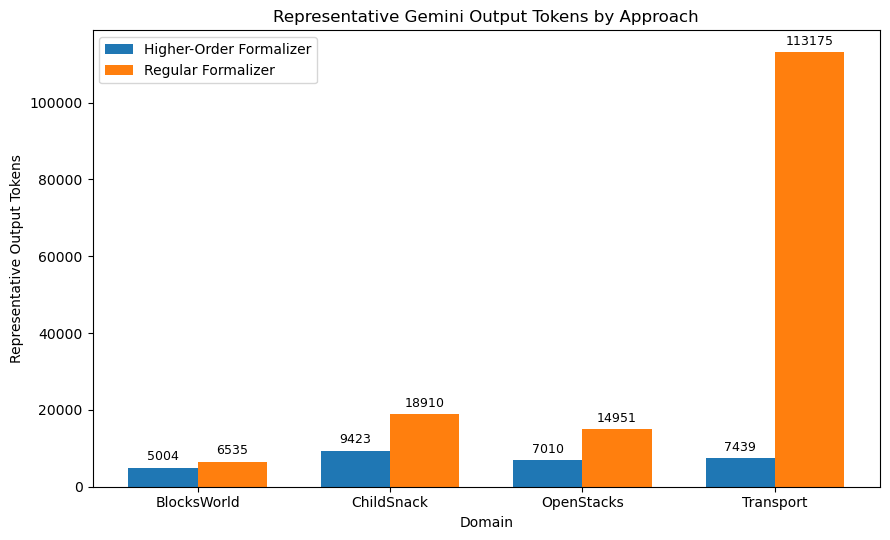

In [10]:
# Cell 6: Plot representative output-token comparison

import matplotlib.pyplot as plt
import numpy as np

plot_df = comparison.copy()

domains = plot_df["domain"].tolist()
higher_order_tokens = plot_df["higher_order_formalizer"].tolist()
regular_tokens = plot_df["regular_formalizer"].tolist()

x = np.arange(len(domains))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 5.5))

bars_higher = ax.bar(
  x - width / 2,
  higher_order_tokens,
  width,
  label="Higher-Order Formalizer",
)

bars_regular = ax.bar(
  x + width / 2,
  regular_tokens,
  width,
  label="Regular Formalizer",
)

ax.set_ylabel("Representative Output Tokens")
ax.set_xlabel("Domain")
ax.set_title("Representative Gemini Output Tokens by Approach")
ax.set_xticks(x)
ax.set_xticklabels(domains)
ax.legend()

ax.bar_label(bars_higher, padding=3, fontsize=9)
ax.bar_label(bars_regular, padding=3, fontsize=9)

fig.tight_layout()
plt.show()